# EyePACS -- Module 1 extra data + Module 2 non-longitudinal pretraining

Uses the resized EyePACS dataset
([kaggle.com/datasets/mohlamin/resized-eyepacs-diabetic-retinopathy-dataset](https://www.kaggle.com/datasets/mohlamin/resized-eyepacs-diabetic-retinopathy-dataset),
`all_labels.csv`, ICDR 0-4) for two things:

* **Part A -- Module 1:** builds an EyePACS grading pickle (patient-level split, both eyes of a
  patient stay in the same split) and, optionally, trains DRG-Net's classifier on it.
* **Part B -- Module 2 stage 1:** runs Module 1's lesion segmenters over (a subset of) EyePACS,
  builds per-stage biomarker profiles (EX/HE/MA/SE area + count, LBS), and pretrains the
  Module 2 Generator/Discriminator on single graded images (StarGAN-style stage translation +
  biomarker-profile loss). Checkpoints go to Drive so **notebook 06** can fine-tune from them
  (`USE_NONLONG_PRETRAIN = True` there).

**Run after notebooks 01-03** (needs the FGADR classifier + segmentation checkpoints on Drive).

**Manual prerequisite:** download the Kaggle zip and upload it to `My Drive/Thesis_Datasets/`
(set `EYEPACS_ZIP` below if you named it differently).

In [1]:
from google.colab import drive
drive.mount('/content/drive')
# Free Drive space: the training notebooks save checkpoints and caches here (several GB in total).
# Deleted or overwritten files stay in the Drive Trash and still count -- empty it if space is low.
import shutil as _shutil
try:
    _du = _shutil.disk_usage('/content/drive/MyDrive')
    print(f'Google Drive: {_du.free / 1e9:.1f} GB free of {_du.total / 1e9:.1f} GB')
    if _du.free < 10e9:
        print('\u26a0 Under 10 GB free on Google Drive -- model files may fail to save. Empty the Trash '
              '(drive.google.com/drive/trash) or free space before training.')
except OSError:
    pass

import getpass, os, glob, json
GITHUB_TOKEN = getpass.getpass('GitHub Personal Access Token (repo scope): ')

REPO_OWNER = 'Mieka068'
REPO_NAME = 'DRProgression'
REPO_BRANCH = 'mod-2-NonLongIntegration'  # <-- change to 'main' once this branch is merged
REPO_CODE_SUBDIR = 'M2-DRProgression-VerM-module1-fgadr-poc'

DRIVE_DATA_DIR = '/content/drive/MyDrive/Thesis_Datasets'
assert os.path.isdir(DRIVE_DATA_DIR), f"Not found: {DRIVE_DATA_DIR}"
MODULE2_RUNS_DIR = os.path.join(DRIVE_DATA_DIR, 'module2_runs')
os.makedirs(MODULE2_RUNS_DIR, exist_ok=True)

# Which Module 1 models the pipeline uses -- set the SAME value in notebooks 04_05 and 06-10:
#   'drgnet' -- notebook 11's DRG-Net replication checkpoints (module1_runs/drgnet_replication/)
#   'poc'    -- notebooks 02/03's original POC checkpoints (module1_runs/)
# Everything built from Module 1's outputs (Module 1 caches, Module 2 runs, figures) gets a
# '_drgnet' suffix for 'drgnet', so the two pipelines never overwrite each other's results.
MODULE1_SOURCE = 'drgnet_combined'
assert MODULE1_SOURCE in ('drgnet_combined', 'drgnet', 'poc'), MODULE1_SOURCE
RUN_TAG = {'drgnet_combined': '_drgnet_comb', 'drgnet': '_drgnet', 'poc': ''}[MODULE1_SOURCE]
MODULE1_RUNS = os.path.join(DRIVE_DATA_DIR, 'module1_runs', *(['drgnet_replication'] if MODULE1_SOURCE != 'poc' else []))
# Lesion segmenters: <MODULE1_RUNS>/segmentation/<SEG_MODEL_PREFIX><lesion>/model_2.pth.tar --
# FGADR + DDR combined (notebook 11) or FGADR only. The classifier is FGADR's either way.
SEG_MODEL_PREFIX = 'comb_models_' if MODULE1_SOURCE == 'drgnet_combined' else 'models_FGADR_NO_TATL_'
MODULE1_CACHE_DIR = os.path.join(DRIVE_DATA_DIR, 'module1_cache' + RUN_TAG)
os.makedirs(MODULE1_CACHE_DIR, exist_ok=True)
print('Module 1 source:', MODULE1_SOURCE, '| models:', MODULE1_RUNS, '| caches:', MODULE1_CACHE_DIR)

EYEPACS_ZIP = os.path.join(DRIVE_DATA_DIR, 'resized-eyepacs-diabetic-retinopathy-dataset.zip')  # <-- your zip name
if not os.path.isfile(EYEPACS_ZIP):
    _z = sorted(glob.glob(os.path.join(DRIVE_DATA_DIR, '*eyepacs*.zip')) + glob.glob(os.path.join(DRIVE_DATA_DIR, '*EyePACS*.zip')))
    assert _z, f"No EyePACS zip found in {DRIVE_DATA_DIR} -- upload it there first"
    EYEPACS_ZIP = _z[0]
print('EyePACS zip:', EYEPACS_ZIP)

Mounted at /content/drive
Google Drive: 175.2 GB free of 214.7 GB
GitHub Personal Access Token (repo scope): ··········
Module 1 source: drgnet_combined | models: /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication | caches: /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb
EyePACS zip: /content/drive/MyDrive/Thesis_Datasets/resized-eyepacs-diabetic-retinopathy-dataset.zip


In [2]:
# Unzip locally on the Colab VM disk (much faster than reading off Drive). -n = skip existing.
EYEPACS_DIR = '/content/data/eyepacs'
os.makedirs(EYEPACS_DIR, exist_ok=True)
!unzip -q -n "{EYEPACS_ZIP}" -d "{EYEPACS_DIR}"

import pandas as pd
_csv = glob.glob(f'{EYEPACS_DIR}/**/all_labels.csv', recursive=True)
assert _csv, 'all_labels.csv not found in the zip -- check: !ls -R /content/data/eyepacs | head'
LABELS_CSV = _csv[0]
_df = pd.read_csv(LABELS_CSV)
print(LABELS_CSV, _df.shape)
print(_df.head())
print('Columns:', list(_df.columns))  # the loaders auto-detect image/grade columns from these

/content/data/eyepacs/all_labels.csv (88700, 3)
      image  level Usage
0   10_left      0   NaN
1  10_right      0   NaN
2   13_left      0   NaN
3  13_right      0   NaN
4   15_left      1   NaN
Columns: ['image', 'level', 'Usage']


In [3]:
# Clone this repo. Skips cleanly if already cloned in this runtime.
%cd /content
if not os.path.isdir(f'/content/{REPO_NAME}'):
    !git clone --branch {REPO_BRANCH} https://{GITHUB_TOKEN}@github.com/{REPO_OWNER}/{REPO_NAME}.git {REPO_NAME}
REPO_CODE_DIR = f'/content/{REPO_NAME}/{REPO_CODE_SUBDIR}'
assert os.path.isdir(REPO_CODE_DIR), f"Not found: {REPO_CODE_DIR} -- check REPO_BRANCH/REPO_CODE_SUBDIR above"
%cd {REPO_CODE_DIR}
!pip install -q pandas openpyxl segmentation-models-pytorch matplotlib scipy torchmetrics torch-fidelity

/content
Cloning into 'DRProgression'...
remote: Enumerating objects: 605, done.
remote: Counting objects: 100% (284/284), done.
remote: Compressing objects: 100% (200/200), done.
remote: Total 605 (delta 167), reused 185 (delta 84), pack-reused 321 (from 1)
Receiving objects: 100% (605/605), 9.13 MiB | 7.68 MiB/s, done.
Resolving deltas: 100% (337/337), done.
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 58.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.6/85.6 kB 9.5 MB/s eta 0:00:00


## Part A -- Module 1: EyePACS grading data

`COMBINE_WITH_FGADR = True` merges FGADR's pickle in (train on both). That changes the test
set, so keep the FGADR-only run from notebook 02 for comparison with the DRG-Net paper.

In [4]:
COMBINE_WITH_FGADR = False
MAX_PER_GRADE = None   # e.g. 3000 to shorten Module 1 training -- EyePACS is ~73% grade 0

PKL_DIR = os.path.join(DRIVE_DATA_DIR, 'module1_pkl')
os.makedirs(PKL_DIR, exist_ok=True)
EYEPACS_PKL = os.path.join(PKL_DIR, 'eyepacs_classification_pkl.pkl')
_extra = ''
if COMBINE_WITH_FGADR:
    _extra += f' --combine-with "{os.path.join(PKL_DIR, "fgadr_classification_pkl.pkl")}"'
if MAX_PER_GRADE:
    _extra += f' --max-per-grade {MAX_PER_GRADE}'
%cd {REPO_CODE_DIR}
!python module1/dataprep/make_eyepacs_classification_pkl.py --eyepacs-root "{EYEPACS_DIR}" --out "{EYEPACS_PKL}"{_extra}

/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
  Labels: all_labels.csv -- image <- 'image', grade <- 'level' (88700 rows; columns ['image', 'level', 'Usage'])
✓ 88700 labelled images found (0 labelled but missing on disk)
  Official split from column 'Usage': ['private', 'public']
  ⚠ 35126 images with no official split -- dropped
  Official split read from labels CSV column
✓ train: 0 images, per grade [0, 0, 0, 0, 0]
✓ val  : 10906 images, per grade [8130, 720, 1579, 237, 240]
✓ test : 42668 images, per grade [31402, 3042, 6281, 977, 966]
✓ wrote /content/drive/MyDrive/Thesis_Datasets/module1_pkl/eyepacs_classification_pkl.pkl (split=official)


In [5]:
# OPTIONAL (long: ~35k training images at 512px x 25 epochs is many hours on Colab -- set
# MAX_PER_GRADE above to shorten; resumes after a disconnect). Trains DRG-Net's classifier on the EyePACS pickle with
# module1/configs/eyepacs_poc.yaml. Same DRG-Net setup + compatibility patches as notebook 02.
RUN_EYEPACS_CLASSIFIER_TRAINING = False

if RUN_EYEPACS_CLASSIFIER_TRAINING:
    %cd /content
    if not os.path.isdir('/content/dr-joint-learning'):
        !git clone https://github.com/DFKI-Interactive-Machine-Learning/dr-joint-learning.git dr-joint-learning
        !cd dr-joint-learning && git checkout 0da1bbe885f438390a0e94ec486283d9b21d5547
    !sed -i 's/fillcolor=aug_args.value_fill/fill=aug_args.value_fill/' /content/dr-joint-learning/dr_classification/data/transforms.py
    !pip install -q munch self-attention-cv pretrainedmodels cnn_finetune ipdb
    # Checkpoint/resume (same patch as notebook 11): the training state is saved every epoch on the
    # VM disk and copied to Drive every 5 epochs and at the end (rewriting it on Drive every epoch
    # would fill the Drive with old copies); re-running this cell after a disconnect continues from
    # the last Drive copy.
    !python {REPO_CODE_DIR}/module1/drgnet_resume_patch.py /content/dr-joint-learning
    import re, shutil
    _drive_saves = f'{DRIVE_DATA_DIR}/module1_runs/classification/eyepacs/saves'
    _local_saves = '/content/drg_local/classification/eyepacs/saves'
    os.makedirs(_drive_saves, exist_ok=True); os.makedirs(_local_saves, exist_ok=True)
    for _f in os.listdir(_drive_saves):  # new runtime: resume from the Drive copy
        if not os.path.isfile(os.path.join(_local_saves, _f)):
            shutil.copy2(os.path.join(_drive_saves, _f), os.path.join(_local_saves, _f))
    _cfg = open(f'{REPO_CODE_DIR}/module1/configs/eyepacs_poc.yaml').read()
    _cfg = re.sub(r"save_path: .*", f"save_path: '{_local_saves}'", _cfg, count=1)
    _cfg = re.sub(r"log_path: .*", "log_path: '/content/drg_local/classification/eyepacs/logs'", _cfg, count=1)
    open('/content/dr-joint-learning/dr_classification/configs/eyepacs_poc.yaml', 'w').write(_cfg)
    %cd /content/dr-joint-learning/dr_classification
    !DRG_CLS_RESUME=1 DRG_CLS_MIRROR_DIR="{_drive_saves}" DRG_CLS_MIRROR_EVERY=5 python main.py -c configs/eyepacs_poc.yaml -overwrite
    for _f in ('best_validation_weights.pt', 'final_weights.pt', 'resume_state.pt'):
        if os.path.isfile(os.path.join(_local_saves, _f)):
            shutil.copy2(os.path.join(_local_saves, _f), os.path.join(_drive_saves, _f))
    assert os.path.isfile(os.path.join(_drive_saves, 'final_weights.pt')), (
        f'final_weights.pt not saved to {_drive_saves} -- is your Google Drive full? (drive.google.com/settings/storage)')
    %cd {REPO_CODE_DIR}
else:
    print('Skipped (RUN_EYEPACS_CLASSIFIER_TRAINING = False).')

Skipped (RUN_EYEPACS_CLASSIFIER_TRAINING = False).


## Part B -- Module 2 stage 1: biomarker profiles + non-longitudinal pretraining

Module 1 over all ~88k images takes hours, so by default a grade-stratified subset
(`PER_GRADE_SUBSET` images per grade) is cached. `--resume` + `--save-every` let you re-run this
cell after a disconnect and continue where it stopped. The classifier's predicted grade isn't
used here (EyePACS has real labels) -- only the lesion masks/stats matter.

In [6]:
CLASSIFIER_RUN = 'fgadr'   # Module 1 classifier for the cache ('eyepacs' = an EyePACS-trained one)

# Locate the Module 1 classifier + segmentation checkpoints (same discovery logic as
# notebooks 04-08). HE/SE are included automatically once they exist on Drive.
SEG_DIR   = os.path.join(MODULE1_RUNS, 'segmentation')
CLS_SAVES = os.path.join(MODULE1_RUNS, 'classification', CLASSIFIER_RUN, 'saves')
# Classifier input normalisation must match its training config (eyepacs_poc.yaml differs).
CLS_NORM_ARGS = ' --classifier-norm eyepacs' if CLASSIFIER_RUN == 'eyepacs' else ""

_pref  = ['final_weights.pt', 'best_validation_weights.pt']
_cands = [os.path.join(CLS_SAVES, n) for n in _pref] + sorted(
    glob.glob(os.path.join(CLS_SAVES, '*.pt')), key=os.path.getmtime, reverse=True)
CLS_CKPT = next((p for p in _cands if os.path.isfile(p)), None)
assert CLS_CKPT, f"No classifier .pt in {CLS_SAVES} -- run notebook 02/03 (MODULE1_SOURCE='poc') or 11 ('drgnet' / 'drgnet_combined') first"

SEG_ARGS = ''
for _lesion in ['EX', 'MA', 'HE', 'SE']:
    _p = os.path.join(SEG_DIR, f'{SEG_MODEL_PREFIX}{_lesion.lower()}', 'model_2.pth.tar')
    if os.path.isfile(_p):
        SEG_ARGS += f' --seg-checkpoint {_lesion}="{_p}"'
    print(f'{_lesion} seg :', _p if os.path.isfile(_p) else 'not trained yet')
assert 'EX=' in SEG_ARGS and 'MA=' in SEG_ARGS, f'EX/MA segmentation checkpoints missing in {SEG_DIR} -- run notebook 03 (poc) or 11 (drgnet) first'
print('classifier:', CLS_CKPT)

EX seg : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication/segmentation/comb_models_ex/model_2.pth.tar
MA seg : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication/segmentation/comb_models_ma/model_2.pth.tar
HE seg : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication/segmentation/comb_models_he/model_2.pth.tar
SE seg : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication/segmentation/comb_models_se/model_2.pth.tar
classifier: /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication/classification/fgadr/saves/final_weights.pt


In [7]:
PER_GRADE_SUBSET = 1500   # images per grade to run Module 1 on; None = all images (hours)

from crosssectional_dataset import load_labels, sample_per_grade
_labels = load_labels(LABELS_CSV)
if PER_GRADE_SUBSET:
    _labels = sample_per_grade(_labels, PER_GRADE_SUBSET, seed=0)
IMAGE_LIST = '/content/eyepacs_module1_subset.txt'
_labels['image_id'].to_csv(IMAGE_LIST, index=False, header=False)
print(f'{len(_labels)} images queued, per grade:', _labels['grade'].value_counts().sort_index().tolist())

EYEPACS_CACHE = os.path.join(MODULE1_CACHE_DIR, 'module1_outputs_eyepacs.pt')
%cd {REPO_CODE_DIR}/module1
!python apply_to_progression_data.py --images-dir "{EYEPACS_DIR}" \
    --classifier-checkpoint "{CLS_CKPT}"{SEG_ARGS}{CLS_NORM_ARGS} \
    --image-list "{IMAGE_LIST}" --mask-size 256 \
    --out "{EYEPACS_CACHE}" --resume --save-every 200 --quiet
%cd {REPO_CODE_DIR}

  Labels: all_labels.csv -- image <- 'image', grade <- 'level' (88700 rows; columns ['image', 'level', 'Usage'])
7500 images queued, per grade: [1500, 1500, 1500, 1500, 1500]
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc/module1
Classifier normalisation: fgadr mean=[0.4577976167201996, 0.2596849203109741, 0.13276457786560059] std=[0.28394654393196106, 0.18262696266174316, 0.13211798667907715]
--image-list: 7500 of 7500 listed images found under /content/data/eyepacs
--resume: 7500 images already cached in /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb/module1_outputs_eyepacs.pt, skipping them
✓ wrote 7500 entries to /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb/module1_outputs_eyepacs.pt
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc


  Labels: all_labels.csv -- image <- 'image', grade <- 'level' (88700 rows; columns ['image', 'level', 'Usage'])
✓ 7500/88700 labelled images found in the Module 1 cache
✓ Wrote /content/drive/MyDrive/Thesis_Datasets/module2_runs/stage_biomarker_profiles_drgnet_comb.json
  stage 0: n=1500, characteristic lesions: ['HE']
  stage 1: n=1500, characteristic lesions: ['HE']
  stage 2: n=1500, characteristic lesions: ['HE', 'EX', 'MA']
  stage 3: n=1500, characteristic lesions: ['HE', 'EX', 'MA']
  stage 4: n=1500, characteristic lesions: ['EX', 'HE', 'MA', 'SE']
  0->1: biggest shifts MA_count (d=+0.08), EX_count (d=+0.08), HE_area (d=-0.06); shared: ['MA_count', 'EX_count', 'HE_area', 'EX_area', 'MA_area', 'HE_count', 'lbs', 'SE_count', 'SE_area']
  1->2: biggest shifts EX_area (d=+0.62), EX_count (d=+0.60), MA_count (d=+0.49); shared: ['HE_area', 'SE_area', 'SE_count']
  2->3: biggest shifts MA_count (d=+0.86), HE_count (d=+0.83), MA_area (d=+0.75); shared: ['SE_count']
  3->4: biggest sh

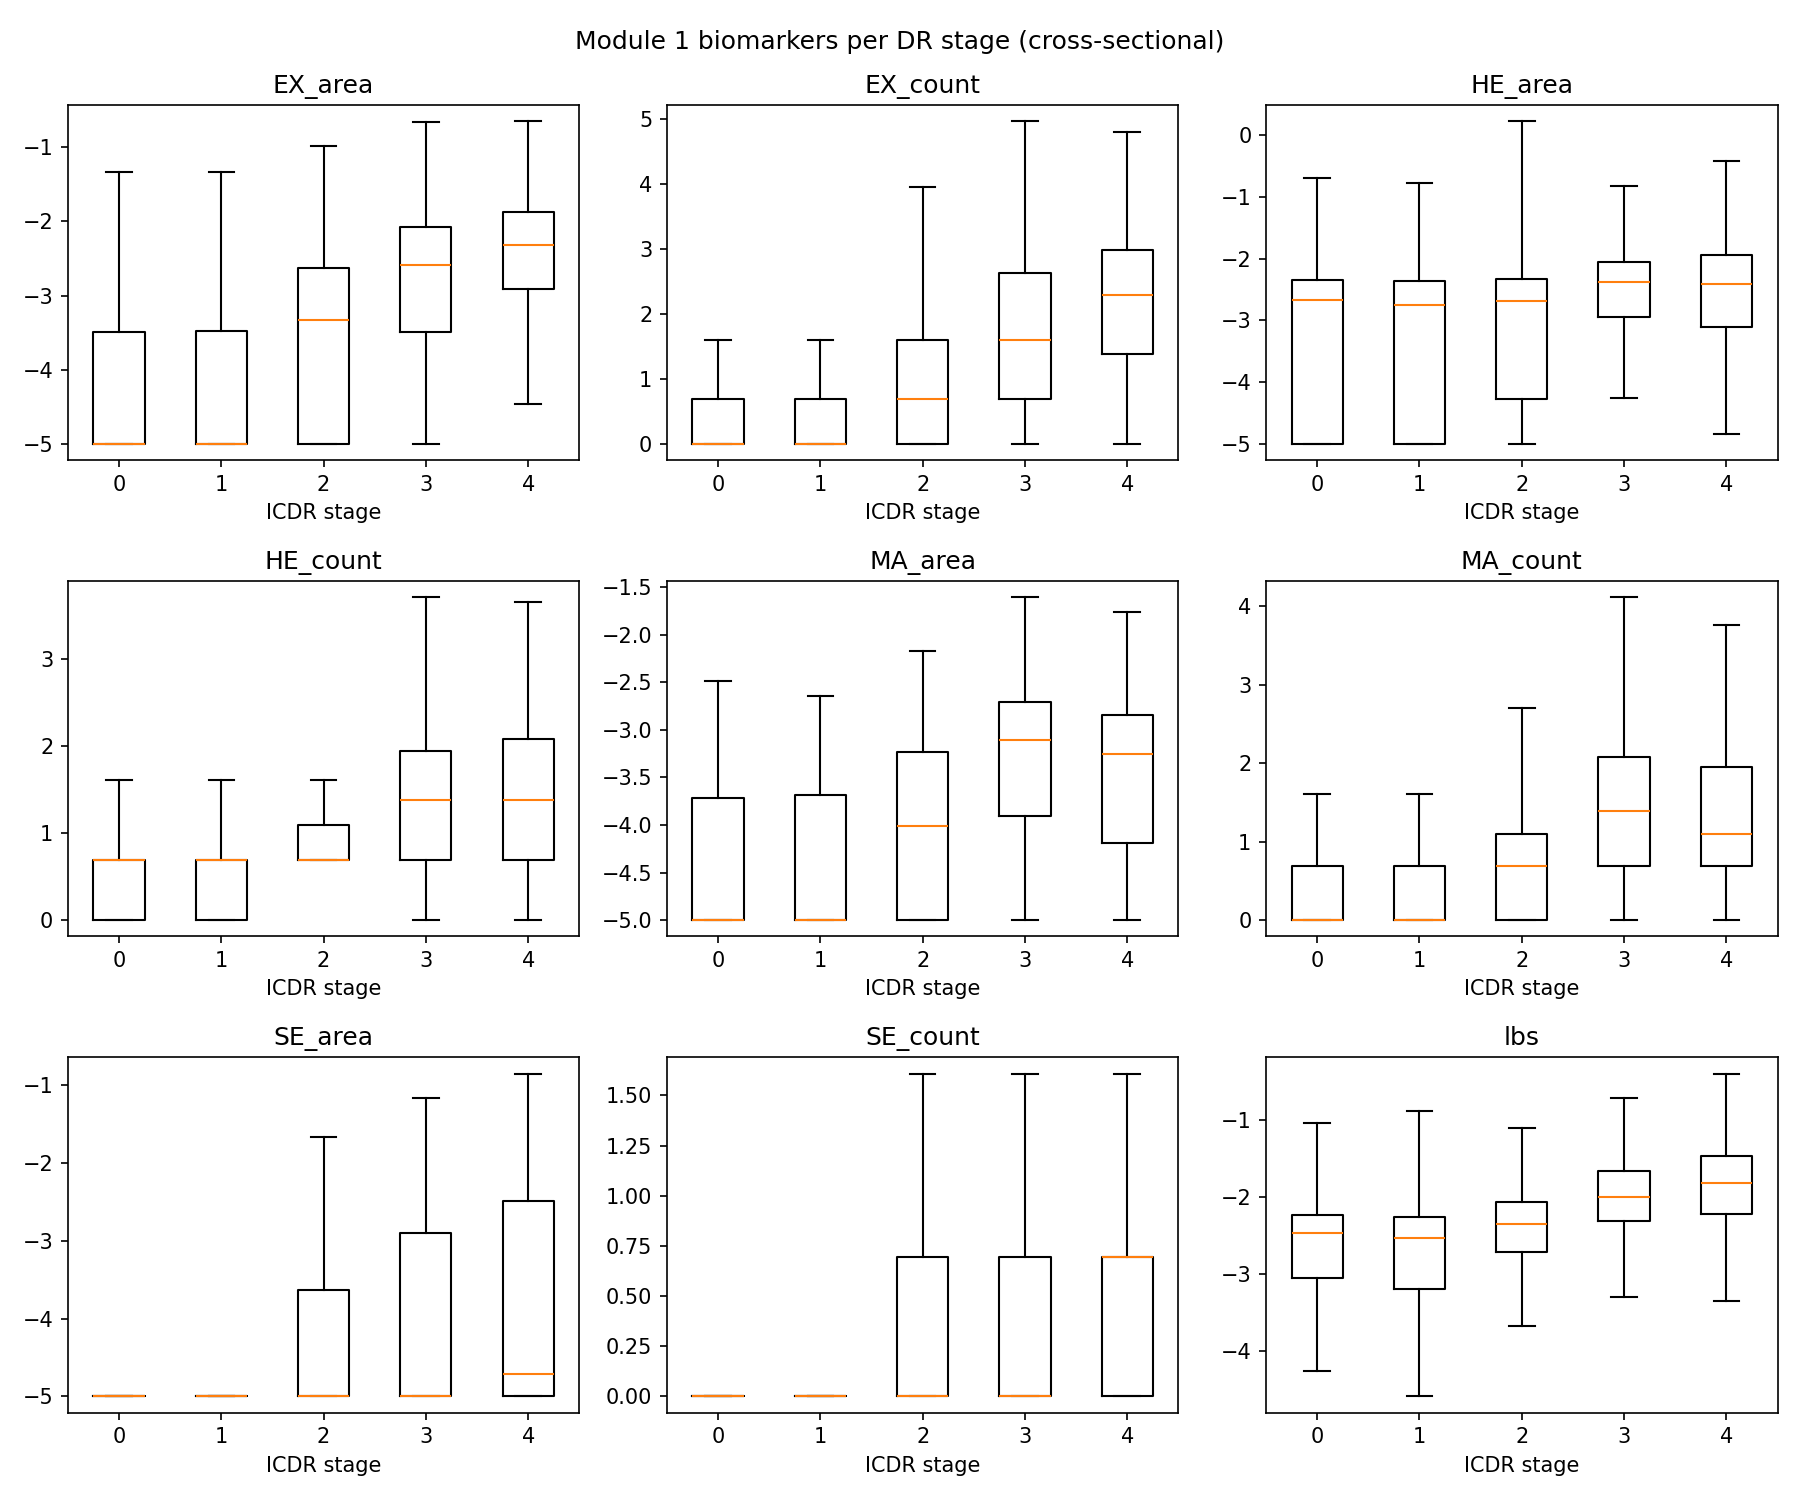

In [8]:
# Which biomarkers characterise each stage / change between adjacent stages.
PROFILES_JSON = os.path.join(MODULE2_RUNS_DIR, f'stage_biomarker_profiles{RUN_TAG}.json')
PROFILES_FIG = os.path.join(MODULE2_RUNS_DIR, f'stage_biomarker_profiles{RUN_TAG}.png')
!python stage_biomarker_profiles.py --module1-cache "{EYEPACS_CACHE}" --labels-csv "{LABELS_CSV}" \
    --out "{PROFILES_JSON}" --fig "{PROFILES_FIG}"

from IPython.display import Image as IPImage, display
display(IPImage(PROFILES_FIG))

In [9]:
# Stage-1 pretraining. Saved straight to Drive so notebook 06 can fine-tune from it in a later
# session. NUM_EPOCHS: 40 (was 20); lower NUM_EPOCHS / SAMPLES_PER_EPOCH for a quicker first run.
# Training state is saved every epoch on the runtime's disk and copied to Drive (resume_state.pt)
# every 10 epochs and after the last one -- after a disconnect, re-run this cell and it continues
# from the last Drive copy; raising NUM_EPOCHS later continues the same run. To start over, delete
# it and restart the runtime.
NUM_EPOCHS = 40
SAMPLES_PER_EPOCH = 20000
NONLONG_DIR = os.path.join(MODULE2_RUNS_DIR, 'nonlong_pretrain' + RUN_TAG)

!python train_module2_nonlong_pretrain.py --dataset-dir "{EYEPACS_DIR}" --preset eyepacs_resized \
    --module1-cache "{EYEPACS_CACHE}" --profiles "{PROFILES_JSON}" \
    --num-epochs {NUM_EPOCHS} --samples-per-epoch {SAMPLES_PER_EPOCH} --num-workers 2 \
    --save-dir "{NONLONG_DIR}" --sample-dir "{NONLONG_DIR}/samples" \
    --resume-state "{NONLONG_DIR}/resume_state.pt"
for _f in ('final-G.ckpt', 'final-D.ckpt', 'resume_state.pt'):
    assert os.path.isfile(os.path.join(NONLONG_DIR, _f)) and os.path.getsize(os.path.join(NONLONG_DIR, _f)) > 0, (
        f'{_f} not found in {NONLONG_DIR}: if the training output above ends with an error, training stopped '
        f'early -- fix that and re-run this cell (it resumes); if training finished, your Google Drive may be '
        f'full -- check drive.google.com/settings/storage and empty the Trash.')
print('Pretrained Generator/Discriminator saved to Drive:', NONLONG_DIR)

Module 2 stage-1 pretraining on cross-sectional data
Device: cuda | dataset: /content/data/eyepacs (eyepacs_resized)

[1/4] Loading cross-sectional dataset...
  Labels: all_labels.csv -- image <- 'image', grade <- 'level' (88700 rows; columns ['image', 'level', 'Usage'])
✓ Loaded Module 1 cache: 7500 images, 7500/88700 labelled images covered (/content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb/module1_outputs_eyepacs.pt)
✓ Cross-sectional (eyepacs_resized): 88700 images, per grade [65342, 6205, 13152, 2087, 1914]
✓ Split: 79831 train / 8869 val (grade-balanced sampling)
✓ Biomarker profiles loaded (/content/drive/MyDrive/Thesis_Datasets/module2_runs/stage_biomarker_profiles_drgnet_comb.json) -- biomarker losses ON

[2/4] Initializing models...

[3/4] Training for 40 epochs (1250 batches/epoch)...
[resume] restored /content/local_drive_twin/MyDrive/Thesis_Datasets/module2_runs/nonlong_pretrain_drgnet_comb/resume_state.pt: 30 epoch(s) already done -- training continues from

/content/drive/MyDrive/Thesis_Datasets/module2_runs/nonlong_pretrain_drgnet_comb/samples/epoch_40.jpg


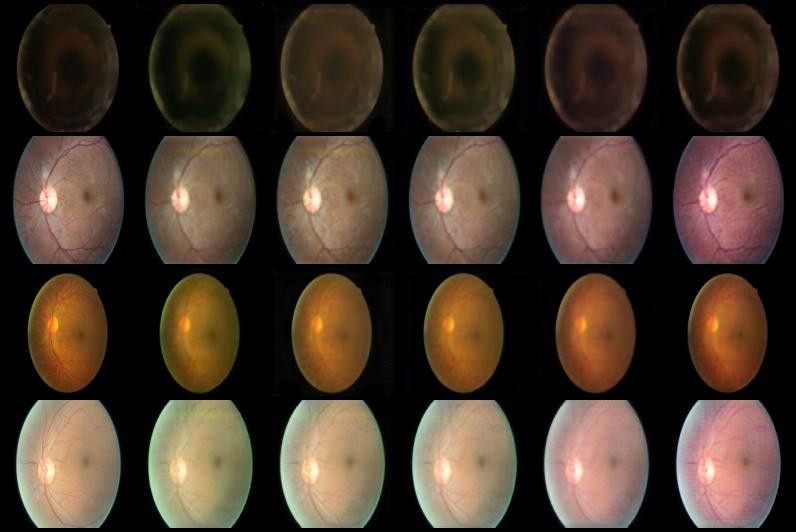

{
  "n_val_images": 320,
  "real_cls_acc": 0.0,
  "fake_cls_agreement": {
    "0": 0.0,
    "1": 0.0,
    "2": 0.0,
    "3": 1.0,
    "4": 0.0
  },
  "bio_mean_abs_z": {
    "0": 0.4292622354295519,
    "1": 0.6775686264038085,
    "2": 0.508534926838345,
    "3": 0.4535506725311279,
    "4": 0.4804775052600437
  },
  "lbs_monotonic_rate": 0.228125
}


In [10]:
# Rows: held-out EyePACS images. Columns: input, then the Generator's stage 0..4 versions.
_samples = sorted(glob.glob(f'{NONLONG_DIR}/samples/epoch_*.jpg'), key=lambda p: int(p.split('_')[-1].split('.')[0]))
if _samples:
    print(_samples[-1]); display(IPImage(_samples[-1]))
_res = os.path.join(NONLONG_DIR, 'nonlong_pretrain_results.json')
print(json.dumps(json.load(open(_res))['metrics'], indent=2) if os.path.isfile(_res) else 'no results yet')

## Next

Open **notebook 06** (same `MODULE1_SOURCE`) and run it: with `USE_NONLONG_PRETRAIN = True` (its
default) it fine-tunes from this notebook's `module2_runs/nonlong_pretrain{RUN_TAG}/final-G.ckpt` /
`final-D.ckpt` on FIRE + LongDR + Tianjin. Optionally run 06 a second time with it `False`, as the
ablation that shows whether EyePACS pretraining helps.

Caveats: biomarkers come from Module 1's *predicted* masks (not manual annotations), and
Module 1 does not segment IRMA/neovascularisation, so the stage-4 profile lacks NV.

## Before closing the runtime

Files written to Drive upload in the background. Run this last cell and wait for the ✓ before
disconnecting or deleting the runtime -- otherwise large files written at the end (model weights,
caches) can be lost.

In [11]:
from google.colab import drive
drive.flush_and_unmount()
print('✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.')

✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.
